# Unit 3 · Exercise 4: Polynomial regression

Executed learning workbook, prepared 5 November 2026. Adapted from the supplied University of Essex Online notebook. The original examples appear first, followed by controlled experiments and interpretation.

**How to use:** Run all cells from top to bottom. Find **Change these values**, change one setting, then run all again. Keep the random seed fixed when comparing a change in noise or model settings. Read the printed results alongside the plots; outputs describe these teaching datasets only.

**Corrections and provenance:** Original cubic fit and arrays are retained. Corrected the R² explanation: it measures improvement over the evaluated data’s mean prediction, can be negative, and does not prove causation or predictive validity. “17:00 (5 p.m.).” is corrected to 17:00. Additional polynomial fits use NumPy Polynomial.fit for better numerical conditioning.

The supplied activity specifies running and varying four programs; it does not specify an essay word count or a separate submission format. These notebooks provide execution evidence and observations. Review and personalise the final reflection prompts yourself.

## 1. Original example (corrected where needed)

**Execution note:** All code cells were executed in order in a fresh local IPython session, with actual printed results and figures captured below. This environment does not permit the socket-based Jupyter kernel launcher. Rerun in your own Jupyter or Colab session for your course workflow.

18 cars passing a certain tollboth at different time of the day (x) with different speed (y)

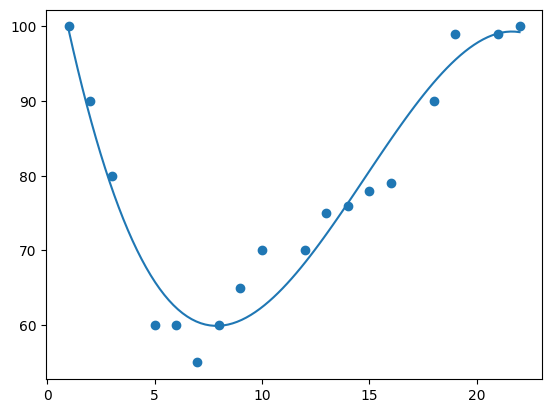

In [1]:
import numpy
import matplotlib.pyplot as plt

x = [1,2,3,5,6,7,8,9,10,12,13,14,15,16,18,19,21,22]
y = [100,90,80,60,60,55,60,65,70,70,75,76,78,79,90,99,99,100]

#NumPy has a method that lets us make a polynomial model
mymodel = numpy.poly1d(numpy.polyfit(x, y, 3))

#specify how the line will display, we start at position 1, and end at position 22
myline = numpy.linspace(1, 22, 100)

plt.scatter(x, y)
plt.plot(myline, mymodel(myline))
plt.show()

R² = 1 − (sum of squared prediction errors / total squared deviation from the mean). Its best value is 1; 0 matches prediction by the evaluation set’s mean, and negative values are possible for poor predictions. A high training R² does not establish causation or good performance on unseen data. R² = 0 does not mean there is no relationship.

In [2]:
import numpy
from sklearn.metrics import r2_score

x = [1,2,3,5,6,7,8,9,10,12,13,14,15,16,18,19,21,22]
y = [100,90,80,60,60,55,60,65,70,70,75,76,78,79,90,99,99,100]

mymodel = numpy.poly1d(numpy.polyfit(x, y, 3))

print(r2_score(y, mymodel(x)))

0.9432150416451026


## Predict Future Values

Let us try to predict the speed of a car that passes the tollbooth at around 17:00 (5 p.m.)

In [3]:
import numpy
from sklearn.metrics import r2_score

x = [1,2,3,5,6,7,8,9,10,12,13,14,15,16,18,19,21,22]
y = [100,90,80,60,60,55,60,65,70,70,75,76,78,79,90,99,99,100]

mymodel = numpy.poly1d(numpy.polyfit(x, y, 3))

speed = mymodel(17)
print(speed)

88.87331269697997


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import r2_score, mean_squared_error
from IPython.display import display
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.2, 'font.size': 10})

## 2. Compare polynomial degrees using fixed held-out points
Degree changes model complexity, not the data. The next section separately changes data points. Four interior observations are withheld before fitting; this tests interpolation, not forecasting a future time period. These few observations cannot provide a robust model selection study.

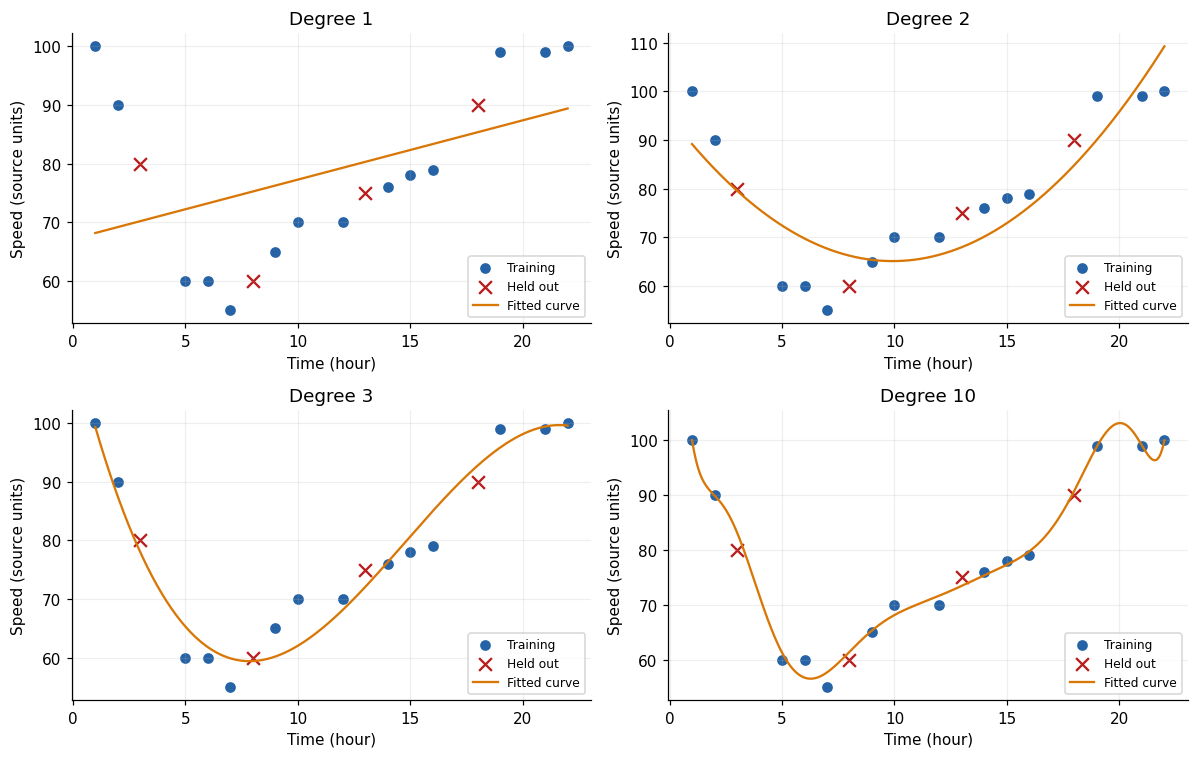

,Degree,Training R2,Test R2,Test RMSE,Prediction at chosen time,Extrapolation at x=25
0,1,0.1761,0.1928,9.7257,84.3478,92.4358
1,2,0.7567,0.7560,5.3478,80.2853,133.9280
2,3,0.9405,0.9559,2.2726,89.0859,91.2145
3,10,0.9921,0.9675,1.9514,83.9810,1831.6390


In [5]:
from numpy.polynomial import Polynomial
# Change these values, then run all cells again.
DEGREES = [1, 2, 3, 10]
NOISE_SD = 10
OUTLIER_INCREASE = 60
RANDOM_SEED = 42
PREDICT_TIME = 17
xx=np.array([1,2,3,5,6,7,8,9,10,12,13,14,15,16,18,19,21,22],dtype=float)
yy=np.array([100,90,80,60,60,55,60,65,70,70,75,76,78,79,90,99,99,100],dtype=float)
test_indices=np.array([2,6,10,14])
train_mask=np.ones(len(xx),dtype=bool); train_mask[test_indices]=False
assert len(DEGREES)==4 and all(1 <= d < sum(train_mask) for d in DEGREES)
grid=np.linspace(xx.min(),xx.max(),400)
rows=[]
fig,axes=plt.subplots(2,2,figsize=(11,7))
for ax,degree in zip(axes.flat,DEGREES):
    model=Polynomial.fit(xx[train_mask],yy[train_mask],degree)
    train_pred=model(xx[train_mask]); test_pred=model(xx[~train_mask])
    rows.append({'Degree':degree,'Training R2':r2_score(yy[train_mask],train_pred),
                 'Test R2':r2_score(yy[~train_mask],test_pred),
                 'Test RMSE':np.sqrt(mean_squared_error(yy[~train_mask],test_pred)),
                 'Prediction at chosen time':model(PREDICT_TIME),
                 'Extrapolation at x=25':model(25)})
    ax.scatter(xx[train_mask],yy[train_mask],label='Training',color='#2563a6')
    ax.scatter(xx[~train_mask],yy[~train_mask],marker='x',s=70,label='Held out',color='#b91c1c')
    ax.plot(grid,model(grid),color='#d97706',label='Fitted curve')
    ax.set(title=f'Degree {degree}',xlabel='Time (hour)',ylabel='Speed (source units)');ax.legend(fontsize=8)
fig.tight_layout();plt.show()
polynomial_degrees=pd.DataFrame(rows);display(polynomial_degrees.round(4))

## 3. Change data points while keeping degree = 3
The noise and outlier conditions independently modify the original speed observations. These models use all observations; their R² values are training scores and are not directly comparable to the held-out scores above.

Original all-data cubic prediction at 17:00: 88.8733


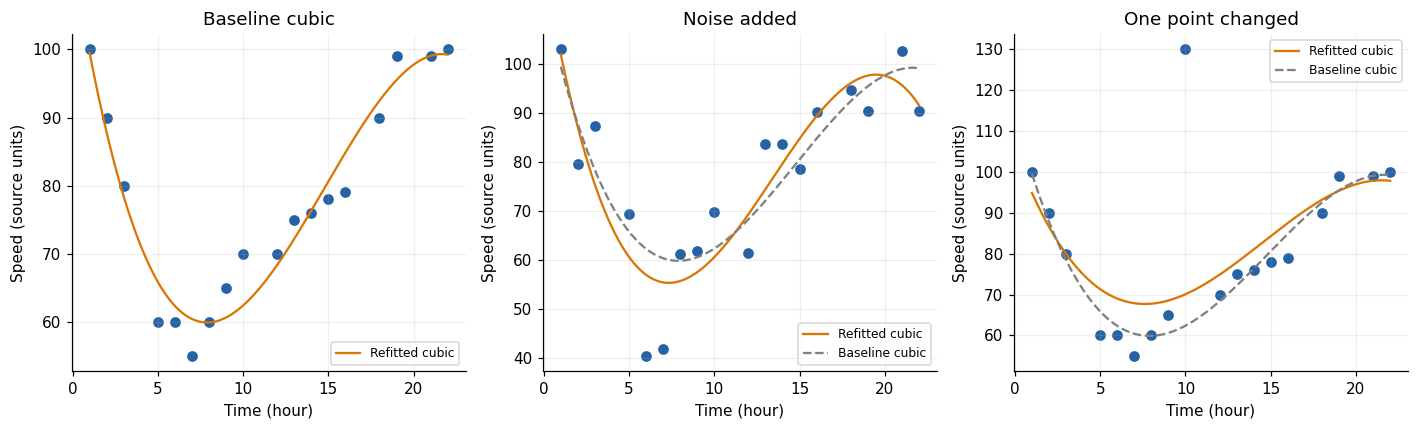

,Scenario,Training R2,Prediction at chosen time
0,Baseline cubic,0.9432,88.8733
1,Noise added,0.7965,93.3072
2,One point changed,0.3299,90.5306


In [6]:
noisy=yy+np.random.default_rng(RANDOM_SEED).normal(0,NOISE_SD,len(yy))
altered=yy.copy(); altered[np.where(xx==10)[0][0]]+=OUTLIER_INCREASE
baseline_poly=Polynomial.fit(xx,yy,3)
rows=[]
fig,axes=plt.subplots(1,3,figsize=(13,4))
for ax,(name,target) in zip(axes,{'Baseline cubic':yy,'Noise added':noisy,'One point changed':altered}.items()):
    model=Polynomial.fit(xx,target,3)
    rows.append({'Scenario':name,'Training R2':r2_score(target,model(xx)),
                 'Prediction at chosen time':model(PREDICT_TIME)})
    ax.scatter(xx,target,color='#2563a6')
    ax.plot(grid,model(grid),color='#d97706',label='Refitted cubic')
    if name!='Baseline cubic': ax.plot(grid,baseline_poly(grid),'--',color='gray',label='Baseline cubic')
    ax.set(title=name,xlabel='Time (hour)',ylabel='Speed (source units)');ax.legend(fontsize=8)
fig.tight_layout();plt.show()
polynomial_changes=pd.DataFrame(rows);display(polynomial_changes.round(4))
print(f'Original all-data cubic prediction at 17:00: {baseline_poly(17):.4f}')

## 4. Interpretation
Compare training R² with held-out RMSE before judging complexity. Higher-degree curves can fit training observations very closely while oscillating between them or extrapolating poorly. Do not assume degree 10 must fail in every sample: interpret the actual scores and plots. The x = 25 column is a mathematical extrapolation beyond the observed range, not a validated next-day traffic forecast. Actual forecasting would require multiple days and a time-aware evaluation.

Changing one y observation or adding noise changes even a cubic curve. The original 17:00 prediction is interpolation because observations exist both before and after 17:00; the source heading “Predict Future Values” does not establish a genuine forecasting design.

**Try next:** Set DEGREES to [1, 2, 3, 6], then restore it before changing NOISE_SD to 20. Explain why a good training fit alone cannot justify a real-world prediction.

## Professional interpretation and personal reflection

- **Dataset suitability:** These are synthetic or small teaching datasets. A strong fit does not establish representativeness, causation or fitness for operational use.
- **Ethical and social issues:** Do not remove inconvenient outliers to improve a score. Investigate whether they are errors or valid cases; rare cases can matter disproportionately in real decisions. Report uncertainty and subgroup limitations.
- **Legal and professional issues:** Before using real personal data, establish the applicable permission or lawful basis, privacy safeguards and data-use terms. These examples do not demonstrate legal compliance. Preserve provenance, units, changes and reproducible execution evidence.
- **Your reflection:** Which change did you rerun? What did you expect, what actually changed, and what would you check before using the model for a real decision? Write your own answers after inspecting the results.

## References
University of Essex Online (2026) *Unit03 Ex4 polynomial_regression* [teaching notebook supplied with the activity].

Scikit-learn developers (n.d.) *r2_score*. Available at: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.r2_score.html (Accessed: 5 November 2026).

NumPy developers (n.d.) *numpy.polynomial.polynomial.Polynomial.fit*. Available at: https://numpy.org/doc/stable/reference/generated/numpy.polynomial.polynomial.Polynomial.fit.html (Accessed: 5 November 2026).